# PV fault classification: CNN demo
Raptor Maps InfraredSolarModules · 20,000 IR images · 12 classes · split 70/15/15 (`splits.csv`)

## 1. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

TRAIN = False          # False = load the trained model (best_cnn.pt); True = train again (~3 min on M3)
DATA_DIR = Path("archive/2020-02-14_InfraredSolarModules/InfraredSolarModules")
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: mps


## 2. Data

In [2]:
split = pd.read_csv("splits.csv")
CLASSES = sorted(split.label.unique())
split["y"] = split.label.map({c: i for i, c in enumerate(CLASSES)})

def load_images(d):
    x = np.stack([np.asarray(Image.open(DATA_DIR / p), dtype=np.float32) / 255 for p in d.path])
    return (x - np.median(x, axis=(1, 2), keepdims=True)) / (x.std(axis=(1, 2), keepdims=True) + 1e-6)

class IRModules(Dataset):
    def __init__(self, d, augment=False):
        self.x = torch.from_numpy(load_images(d)).unsqueeze(1)
        self.y = torch.tensor(d.y.values)
        self.augment = augment
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.x[i]
        if self.augment:
            if torch.rand(1) < 0.5: x = torch.flip(x, [2])
            if torch.rand(1) < 0.5: x = torch.flip(x, [1])
        return x, self.y[i]

train_df, val_df, test_df = [split[split.split == s] for s in ("train", "val", "test")]
train_dl = DataLoader(IRModules(train_df, augment=True), batch_size=128, shuffle=True)
val_dl   = DataLoader(IRModules(val_df), batch_size=512)
test_dl  = DataLoader(IRModules(test_df), batch_size=512)
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)} | classes {len(CLASSES)}")

train 14000 | val 3000 | test 3000 | classes 12


## 3. Model

In [3]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self, n=12):
        super().__init__()
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128 * 5 * 3, 256),
                                        nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.classifier(self.features(x))

model = SmallCNN(len(CLASSES)).to(device)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 782188


## 4. Training

In [4]:
def predict(dl):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in dl:
            ps.append(model(x.to(device)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

if TRAIN:
    counts = np.bincount(train_df.y, minlength=len(CLASSES))
    weights = torch.tensor((len(train_df) / (len(CLASSES) * counts)) ** 0.5, dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=40)
    history, best = [], -1
    for epoch in range(1, 41):
        model.train(); total = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); opt.step()
            total += loss.item() * len(y)
        sched.step()
        f1 = f1_score(*predict(val_dl), average="macro")
        history.append((epoch, total / len(train_df), f1))
        if f1 > best: best = f1; torch.save(model.state_dict(), "best_cnn.pt")
        print(f"epoch {epoch:2d}  loss {history[-1][1]:.3f}  val macro-F1 {f1:.3f}")
    h = np.array(history)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(h[:, 0], h[:, 1]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(h[:, 0], h[:, 2]); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()
else:
    print("TRAIN = False → using saved model best_cnn.pt (trained 40 epochs)")

model.load_state_dict(torch.load("best_cnn.pt", map_location=device))

TRAIN = False → using saved model best_cnn.pt (trained 40 epochs)


<All keys matched successfully>

## 5. Results

In [5]:
yt, pt = predict(test_dl)
fault_t, fault_p = yt != CLASSES.index("No-Anomaly"), pt != CLASSES.index("No-Anomaly")
summary = pd.DataFrame({
    "Classical baseline (Gradient Boosting)": [0.690, 0.519, 0.849],
    "Small CNN": [accuracy_score(yt, pt), f1_score(yt, pt, average="macro"), accuracy_score(fault_t, fault_p)],
}, index=["Test accuracy (12 classes)", "Test macro-F1 (12 classes)", "Fault vs no-fault accuracy"]).round(3)
print(summary.to_string())

                            Classical baseline (Gradient Boosting)  Small CNN
Test accuracy (12 classes)                                   0.690      0.794
Test macro-F1 (12 classes)                                   0.519      0.659
Fault vs no-fault accuracy                                   0.849      0.922


In [6]:
print(classification_report(yt, pt, target_names=CLASSES, digits=2))

                precision    recall  f1-score   support

          Cell       0.60      0.71      0.65       282
    Cell-Multi       0.54      0.39      0.46       193
      Cracking       0.67      0.67      0.67       141
         Diode       0.96      0.95      0.95       225
   Diode-Multi       0.92      0.88      0.90        26
      Hot-Spot       0.58      0.59      0.59        37
Hot-Spot-Multi       0.50      0.59      0.54        37
    No-Anomaly       0.92      0.92      0.92      1500
Offline-Module       0.55      0.61      0.58       124
     Shadowing       0.69      0.66      0.68       158
       Soiling       0.33      0.29      0.31        31
    Vegetation       0.66      0.64      0.65       246

      accuracy                           0.79      3000
     macro avg       0.66      0.66      0.66      3000
  weighted avg       0.79      0.79      0.79      3000



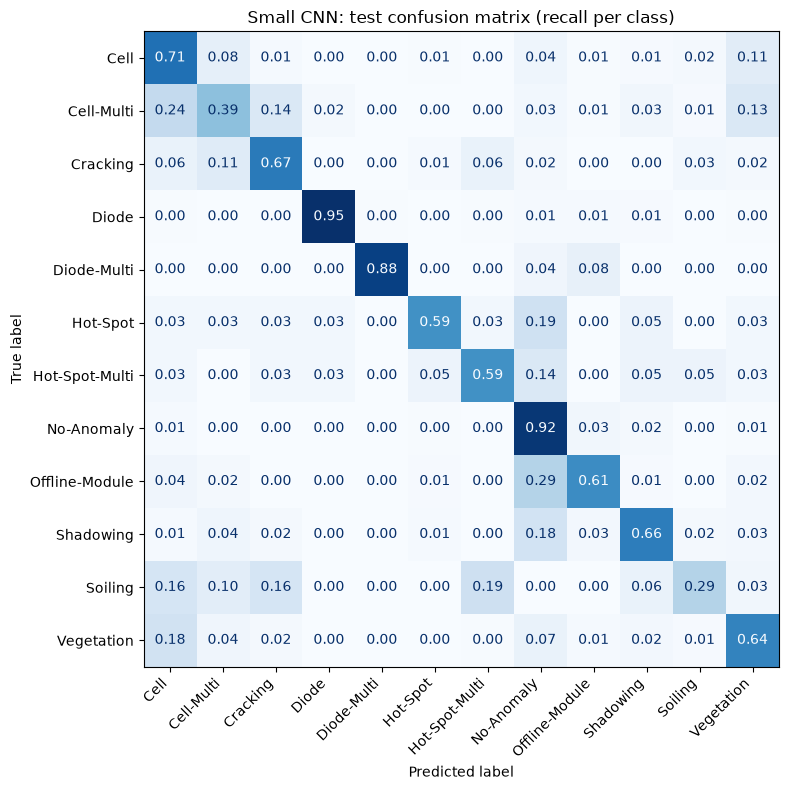

In [7]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(yt, pt, normalize="true"), display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
plt.xticks(rotation=45, ha="right"); ax.set_title("Small CNN: test confusion matrix (recall per class)")
plt.tight_layout(); plt.show()